<a href="https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/09_figures_for_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 09 · Final figures, tables and the IEEE report skeleton
**Goal:** regenerate every figure and table of the report **only from saved result files**, so each number in the paper can be reproduced. Nothing is trained here.

**Writes:** `reports/figures/*.png`, `reports/tables/*.tex`, `reports/main.tex` (an IEEEtran skeleton to fill in).

In [1]:
# ---- Cell 0: Setup (identical at the top of every notebook)
import os, sys, json, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
    IN_COLAB = True
except ImportError:                      # running somewhere else (local / tests)
    PROJECT_ROOT = os.environ.get('PROJECT_ROOT', os.getcwd())
    IN_COLAB = False
sys.path.insert(0, PROJECT_ROOT)
from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
A = cfg['audio']; P = cfg['abs_paths']
RAW, PROCESSED, ALIGN, SPLITS, RESULTS = P['raw'], P['processed'], P['alignments'], P['splits'], P['results']
for d in (PROCESSED, ALIGN, SPLITS, RESULTS):
    os.makedirs(d, exist_ok=True)
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Mounted at /content/drive
Project root: /content/drive/MyDrive/phonetic-tts | Colab: True


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
FIG = os.path.join(PROJECT_ROOT, 'reports/figures'); TAB = os.path.join(PROJECT_ROOT, 'reports/tables')
os.makedirs(FIG, exist_ok=True); os.makedirs(TAB, exist_ok=True)
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 150})
def rd(name):
    p = os.path.join(RESULTS, name)
    if not os.path.exists(p): print('missing:', name); return None
    return pd.read_csv(p)
def tex(df, name, caption, label, **kw):
    d = df.copy()
    d.columns = [str(c).replace('_', ' ') for c in d.columns]               # underscores break LaTeX
    for c in d.columns:
        if not pd.api.types.is_numeric_dtype(d[c]): d[c] = d[c].astype(str).str.replace('_', ' ').str.replace('{', '').str.replace('}', '')
    t = d.to_latex(index=False, float_format='%.3f', caption=caption, label=label, **kw)
    t = t.replace('\\begin{tabular}', '\\resizebox{\\columnwidth}{!}{\\begin{tabular}').replace('\\end{tabular}', '\\end{tabular}}')
    open(os.path.join(TAB, name), 'w').write(t); print('table ->', name)

In [3]:
# ---- Table 1: dataset summary (from notebook 01 and 04)
s1 = json.load(open(os.path.join(RESULTS, '01_dataset_summary.json'))) if os.path.exists(os.path.join(RESULTS, '01_dataset_summary.json')) else {}
s4 = json.load(open(os.path.join(RESULTS, '04_eda_summary.json'))) if os.path.exists(os.path.join(RESULTS, '04_eda_summary.json')) else {}
t1 = pd.DataFrame({'Item': list({**s1, **s4}.keys()), 'Value': [str(v) for v in {**s1, **s4}.values()]}); tex(t1, 'dataset.tex', 'Dataset and alignment summary.', 'tab:data'); t1

table -> dataset.tex


,Item,Value
0,n_clips,13100
1,total_hours,23.92
2,mean_duration_s,6.57
3,max_duration_s,10.1
4,sample_rates,{'22050': 13100}
5,mean_words_per_sec,2.59
6,vocab_size,14775
7,rows_raw_neq_norm,1505
8,n_utts,11416
9,n_phones,777055


In [4]:
# ---- Table 2: model comparison (test set, with bootstrap CIs) and Table 3: ablation
t2 = rd('08_test_table.csv')
if t2 is not None: tex(t2[['model', 'mae_frames', 'ci_low', 'ci_high', 'mae_ms', 'rmse_frames', 'r2']], 'models.tex', 'Duration prediction on the test set (frames of 11.6 ms; 95\\% CI by utterance bootstrap).', 'tab:models')
t3 = rd('08_ablation.csv')
if t3 is not None: tex(t3, 'ablation.tex', 'Feature-group ablation (gradient-boosted trees).', 'tab:ablation')

table -> models.tex
table -> ablation.tex


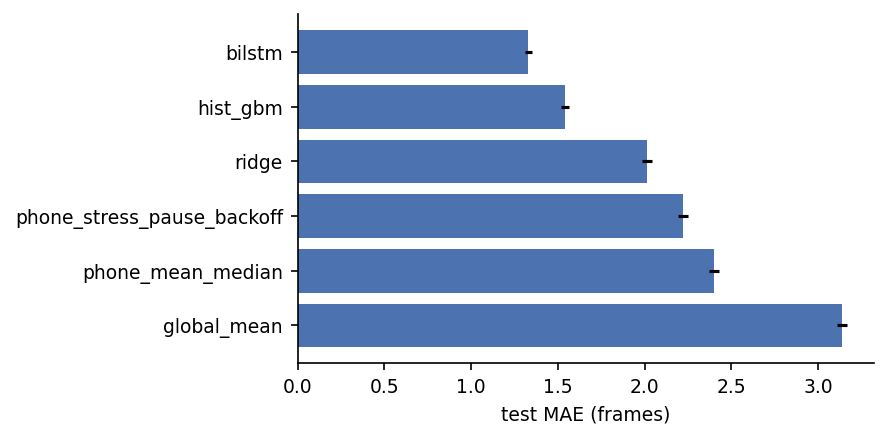

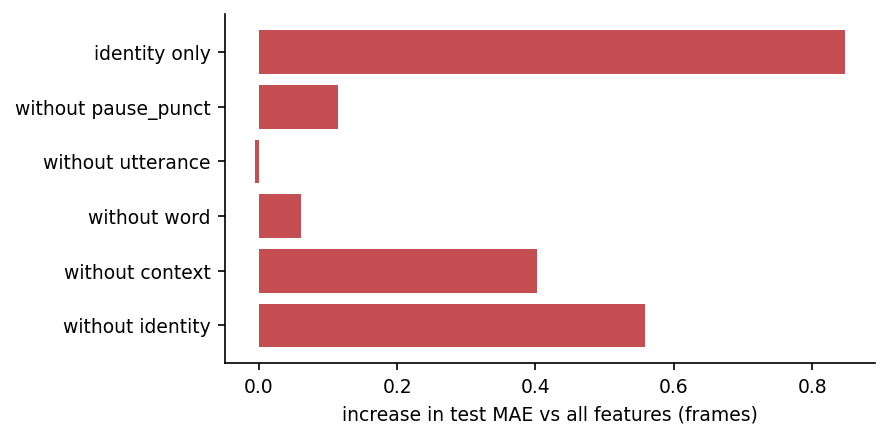

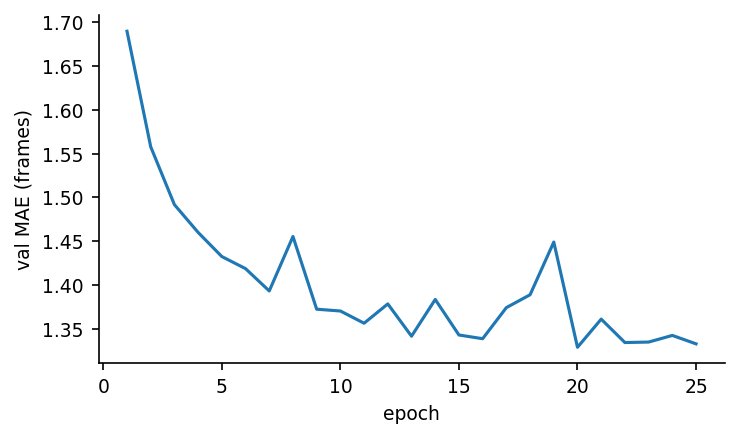

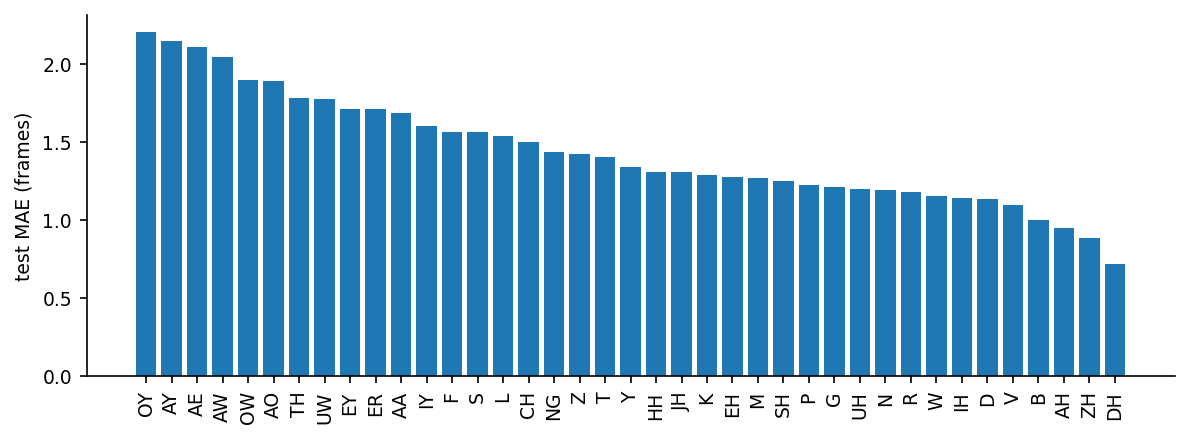

In [5]:
# ---- Figure A: model comparison with error bars
if t2 is not None:
    fig, ax = plt.subplots(figsize=(6, 3)); t = t2.sort_values('mae_frames', ascending=False)
    ax.barh(t.model, t.mae_frames, xerr=[t.mae_frames - t.ci_low, t.ci_high - t.mae_frames], color='#4c72b0'); ax.set_xlabel('test MAE (frames)')
    plt.tight_layout(); plt.savefig(os.path.join(FIG, 'models.png')); plt.show()
# ---- Figure B: ablation
if t3 is not None:
    fig, ax = plt.subplots(figsize=(6, 3)); t = t3.iloc[1:]; ax.barh(t.setting, t.delta_mae_vs_all, color='#c44e52'); ax.set_xlabel('increase in test MAE vs all features (frames)')
    plt.tight_layout(); plt.savefig(os.path.join(FIG, 'ablation.png')); plt.show()
# ---- Figure C: learning curve
h = rd('07_nn_history.csv')
if h is not None:
    fig, ax = plt.subplots(figsize=(5, 3)); ax.plot(h.epoch, h.val_mae_frames); ax.set_xlabel('epoch'); ax.set_ylabel('val MAE (frames)')
    plt.tight_layout(); plt.savefig(os.path.join(FIG, 'learning_curve.png')); plt.show()
# ---- Figure D: per-phone MAE
pp = rd('08_per_phone.csv')
if pp is not None:
    fig, ax = plt.subplots(figsize=(8, 3)); t = pp.sort_values('mae', ascending=False); ax.bar(t.base, t.mae); plt.xticks(rotation=90); ax.set_ylabel('test MAE (frames)')
    plt.tight_layout(); plt.savefig(os.path.join(FIG, 'per_phone.png')); plt.show()

In [6]:
# ---- Copy the notebook-04/08 figures into the report folder under stable names
import shutil
for src, dst in [('04_hmm_vs_real.png', 'hmm_vs_real.png'), ('04_per_phone_box.png', 'per_phone_box.png'), ('04_overall_hist.png', 'overall_hist.png'),
                 ('08_error_analysis.png', 'error_analysis.png'), ('01_clip_duration_hist.png', 'clip_duration.png')]:
    if os.path.exists(os.path.join(RESULTS, src)): shutil.copy(os.path.join(RESULTS, src), os.path.join(FIG, dst)); print('copied', dst)

copied hmm_vs_real.png
copied per_phone_box.png
copied overall_hist.png
copied error_analysis.png
copied clip_duration.png


## The report
The full IEEE report lives in `reports/main.tex` (with `results_macros.tex`). This notebook only refreshes `reports/figures/` and `reports/tables/`, which the report pulls in automatically. It never overwrites the report text.

## Final checklist before Phase 1 submission
- [ ] Every number in the report came from a file in `results/`
- [ ] README results table updated; repo public; no dataset/checkpoints committed
- [ ] `CONTRIBUTIONS.md` filled in per member (the viva is individual)
- [ ] Each member can answer the "Check yourself" questions of **every** notebook